In [1]:
# ==== Cell 1: imports and settings ====
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

PROJECT = Path("/home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim")
DATA_DIR = PROJECT / "data/dataset_20261025_104552_105991"
OUT_DIR = PROJECT / "data/eps_models"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEQ_LEN, SEQ_STRIDE = 128, 64
N_WINDOWS = 2000          # windows per split for the analysis
LATE = slice(64, SEQ_LEN) # "long history" positions
print("device:", DEVICE)

device: cuda


In [2]:
# ==== Cell 2: state layout, the true rule and normalization (same as the Q1 notebook) ====
ON_FOOD, AT_HOME, CARRYING = 0, 1, 2
SEE_FOOD, SEE_HOME = slice(3, 7), slice(7, 11)
SMELL_FOOD, SMELL_HOME = slice(11, 15), slice(15, 19)
N_ACTIONS = 4


def sees_target(s):
    carrying = s[:, CARRYING] > 0.5
    target = np.where(carrying[:, None], s[:, SEE_HOME], s[:, SEE_FOOD])
    return target.max(axis=1) > 0


def signal(s):
    carrying = s[:, CARRYING] > 0.5
    target = np.where(carrying[:, None], s[:, SEE_HOME], s[:, SEE_FOOD])
    smell = np.where(carrying[:, None], s[:, SMELL_HOME], s[:, SMELL_FOOD])
    return np.where(sees_target(s)[:, None], target, smell)


def best_dir(s):
    return signal(s).argmax(axis=1)


def n_ties(s):
    sig = signal(s)
    return (sig == sig.max(axis=1, keepdims=True)).sum(axis=1)


def normalize(s):
    s = s.astype(np.float32).copy()
    s[..., 3:11] /= 20.0
    for blk in (SMELL_FOOD, SMELL_HOME):
        block = s[..., blk]
        lo = block.min(axis=-1, keepdims=True)
        hi = block.max(axis=-1, keepdims=True)
        s[..., blk] = np.where(hi > lo, (block - lo) / np.maximum(hi - lo, 1e-8), 0.0)
    return s

In [3]:
# ==== Cell 3: model definitions (must match the Q1 notebook exactly) ====
class BrainModel(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(5, hidden), nn.ReLU(),
                                   nn.Linear(hidden, hidden), nn.ReLU(),
                                   nn.Linear(hidden, 1))
        self.pick_head = nn.Linear(3, 1)
        self.drop_head = nn.Linear(3, 1)

    def forward(self, x):
        flags = x[:, :3]
        carrying = flags[:, CARRYING:CARRYING + 1] > 0.5
        target = torch.where(carrying, x[:, SEE_HOME], x[:, SEE_FOOD])
        smell = torch.where(carrying, x[:, SMELL_HOME], x[:, SMELL_FOOD])
        per_dir = torch.stack([target, smell], dim=-1)
        tokens = torch.cat([per_dir, flags[:, None, :].expand(-1, 4, -1)], dim=-1)
        a_logit = self.score(tokens).squeeze(-1)
        return a_logit, self.pick_head(flags).squeeze(-1), self.drop_head(flags).squeeze(-1)


class AntGPT(nn.Module):
    def __init__(self, d_in, d_model=64, n_layers=3, n_heads=4, max_len=SEQ_LEN):
        super().__init__()
        self.inp = nn.Linear(d_in, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout=0.0,
                                           batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.out = nn.Linear(d_model, N_ACTIONS)

    def forward(self, x):
        T = x.shape[1]
        h = self.inp(x) + self.pos(torch.arange(T, device=x.device))
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
        h = self.blocks(h, mask=mask, is_causal=True)
        return self.out(self.norm(h))

In [4]:
# ==== Cell 4: load the saved models ====
bundle = torch.load(OUT_DIR / "models_for_q2.pt", map_location=DEVICE)
cfg = bundle["config"]
assert cfg["SEQ_LEN"] == SEQ_LEN and cfg["SEQ_STRIDE"] == SEQ_STRIDE

step_model = BrainModel().to(DEVICE)
step_model.load_state_dict(bundle["brain"])
step_model.eval()

model_B = AntGPT(d_in=cfg["d_in_B"], d_model=cfg["d_model"],
                 n_layers=cfg["n_layers"], n_heads=cfg["n_heads"]).to(DEVICE)
model_B.load_state_dict(bundle["seq_B"])
model_B.eval()
print("loaded brain model and model B")

loaded brain model and model B


In [5]:
# ==== Cell 5: load val and test runs, build model B's input sequences ====
def load_run(run_dir):
    with np.load(run_dir / "traj.npz") as d:
        return dict(name=run_dir.name,
                    state=d["state"].astype(np.float32),
                    action=d["action"].astype(np.int64),
                    prev_action=d["prev_action"].astype(np.float32),
                    eps=float(d["epsilon"]))


@torch.no_grad()
def brain_probs(states_norm, batch=65536):
    shape = states_norm.shape[:-1]
    flat_s = torch.from_numpy(np.ascontiguousarray(states_norm.reshape(-1, 19)))
    out = []
    for start in range(0, len(flat_s), batch):
        a_logit, _, _ = step_model(flat_s[start:start + batch].to(DEVICE))
        out.append(a_logit.softmax(-1).cpu().numpy())
    return np.concatenate(out).reshape(*shape, 4).astype(np.float32)


def build_sequences_B(run_list):
    """Model B's input: [normalized state (19) | brain odds (4) | previous action (4)]."""
    X, Y, EPS = [], [], []
    for r in run_list:
        s = normalize(r["state"])
        x = np.concatenate([s, brain_probs(s), r["prev_action"]], axis=-1).transpose(1, 0, 2)
        X.append(np.ascontiguousarray(x, dtype=np.float32))
        Y.append(np.ascontiguousarray(r["action"].T))
        EPS.append(np.full(x.shape[0], r["eps"], dtype=np.float32))
    return np.concatenate(X), np.concatenate(Y), np.concatenate(EPS)


def all_windows(n_ants, T, seq_len, stride):
    starts = np.arange(0, T - seq_len + 1, stride)
    ants, t0 = np.meshgrid(np.arange(n_ants), starts, indexing="ij")
    return ants.ravel(), t0.ravel()


def get_batch(X, Y, EPS, ants, t0, seq_len):
    t = t0[:, None] + np.arange(seq_len)[None, :]
    return torch.from_numpy(X[ants[:, None], t]), torch.from_numpy(Y[ants[:, None], t]), EPS[ants]


seq = {}
for split in ["val", "test"]:
    run_dirs = sorted(p.parent for p in (DATA_DIR / split).glob("*/traj.npz"))
    seq[split] = build_sequences_B([load_run(r) for r in run_dirs])
    print(f"{split}: X {seq[split][0].shape}")

val: X (2000, 1500, 27)
test: X (2000, 1500, 27)


In [6]:
# ==== Cell 6: run model B and keep the hidden state after every stage ====
STAGES = ["input embedding", "after layer 1", "after layer 2", "after layer 3"]


@torch.no_grad()
def run_with_hidden(model, x):
    """Same computation as model(x), step by step, keeping the hidden state after each stage.
    Each hidden state is (B, T, 64): one 64-number vector per step."""
    T = x.shape[1]
    h = model.inp(x) + model.pos(torch.arange(T, device=x.device))
    mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
    hidden = [h]
    for layer in model.blocks.layers:
        h = layer(h, src_mask=mask, is_causal=True)
        hidden.append(h)
    return model.out(model.norm(h)), hidden


# Check: the step-by-step version must give the same output as the normal forward pass
X, Y, EPS = seq["val"]
ants, t0 = all_windows(len(X), X.shape[1], SEQ_LEN, SEQ_STRIDE)
x, _, _ = get_batch(X, Y, EPS, ants[:64], t0[:64], SEQ_LEN)
with torch.no_grad():
    logits_normal = model_B(x.to(DEVICE))
    logits_steps, _ = run_with_hidden(model_B, x.to(DEVICE))
print("max difference:", (logits_normal - logits_steps).abs().max().item(), "  (want < 1e-4)")

max difference: 0.0   (want < 1e-4)


In [7]:
# ==== Cell 7: collect hidden states, predictions and labels for val and test windows ====
@torch.no_grad()
def collect_hidden(model, data, n_windows=N_WINDOWS, seed=0, batch=256):
    X, Y, EPS = data
    ants, t0 = all_windows(len(X), X.shape[1], SEQ_LEN, SEQ_STRIDE)
    keep = np.random.default_rng(seed).choice(len(ants), size=min(n_windows, len(ants)), replace=False)
    ants, t0 = ants[keep], t0[keep]

    H, P, S, E = [], [], [], []
    for start in range(0, len(ants), batch):
        x, _, e = get_batch(X, Y, EPS, ants[start:start + batch], t0[start:start + batch], SEQ_LEN)
        logits, hidden = run_with_hidden(model, x.to(DEVICE))
        H.append(torch.stack(hidden).cpu().numpy().astype(np.float16))   # (stages, B, L, 64)
        P.append(logits.softmax(-1).cpu().numpy())
        S.append(x[..., :19].numpy())
        E.append(e)
    return dict(hidden=np.concatenate(H, axis=1),   # (stages, W, L, 64)
                probs=np.concatenate(P), states=np.concatenate(S), eps=np.concatenate(E))


val = collect_hidden(model_B, seq["val"], seed=0)
test = collect_hidden(model_B, seq["test"], seed=1)
print("hidden:", val["hidden"].shape, "  eps values per split:", len(np.unique(val["eps"])))

hidden: (4, 2000, 128, 64)   eps values per split: 10


In [8]:
# ==== Cell 8: sanity check, and model B's first result on the untouched test split ====
def implied_eps_late(d):
    W, L, _ = d["probs"].shape
    s = d["states"].reshape(-1, 19)
    clear = (n_ties(s) == 1).reshape(W, L)
    best = best_dir(s).reshape(W, L)
    p_best = np.take_along_axis(d["probs"], best[..., None], axis=-1)[..., 0]
    eps_hat = np.clip((1 - p_best) / 0.75, 0, 1)
    out = {}
    for e in np.unique(d["eps"]):
        m = np.isclose(d["eps"], e)
        out[round(float(e), 1)] = eps_hat[m, LATE][clear[m, LATE]].mean()
    return pd.Series(out)


table = pd.DataFrame({"val": implied_eps_late(val), "test": implied_eps_late(test)})
table["true"] = table.index
print("implied eps after 64-127 steps (val should match the Q1 notebook):")
print(table.round(3))
clean = table.index <= 0.7
print(f"\ntest eps error, eps <= 0.7: {np.abs(table.test - table.true)[clean].mean():.4f}")

implied eps after 64-127 steps (val should match the Q1 notebook):
       val   test  true
0.1  0.172  0.173   0.1
0.2  0.236  0.258   0.2
0.3  0.322  0.332   0.3
0.4  0.418  0.418   0.4
0.5  0.512  0.523   0.5
0.6  0.628  0.628   0.6
0.7  0.700  0.714   0.7
0.8  0.780  0.775   0.8
0.9  0.833  0.835   0.9
1.0  0.871  0.880   1.0

test eps error, eps <= 0.7: 0.0351


probe R² (test split):
                   t=0    t=7   t=31   t=63  t=127
stage                                             
input embedding  0.001  0.001  0.003  0.001  0.026
after layer 1    0.093  0.101  0.153  0.132  0.149
after layer 2    0.110  0.259  0.327  0.364  0.381
after layer 3    0.124  0.369  0.475  0.523  0.581


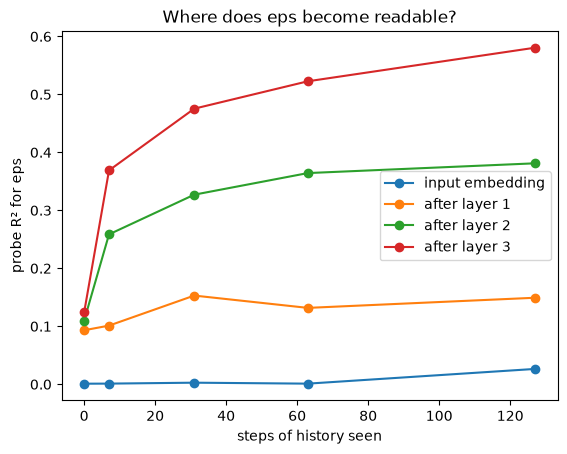

In [9]:
# ==== Cell 9: linear probe per stage and history length ====
# Fit a straight-line readout hidden -> eps on val windows, score it on test windows.
# R² = 1: eps is perfectly readable by a straight line. R² = 0: no better than guessing the average.
PROBE_POSITIONS = [0, 7, 31, 63, 127]


def ridge_fit(Z, y, lam=10.0):
    mu, sd = Z.mean(0), Z.std(0) + 1e-6
    Zs = (Z - mu) / sd
    w = np.linalg.solve(Zs.T @ Zs + lam * np.eye(Z.shape[1]), Zs.T @ (y - y.mean()))
    return lambda Znew: ((Znew - mu) / sd) @ w + y.mean()


def r2(y, y_hat):
    return 1 - ((y - y_hat) ** 2).sum() / ((y - y.mean()) ** 2).sum()


rows = []
for k, stage in enumerate(STAGES):
    row = {"stage": stage}
    for t in PROBE_POSITIONS:
        readout = ridge_fit(val["hidden"][k][:, t].astype(np.float64), val["eps"].astype(np.float64))
        row[f"t={t}"] = r2(test["eps"], readout(test["hidden"][k][:, t].astype(np.float64)))
    rows.append(row)
probe_table = pd.DataFrame(rows).set_index("stage")
print("probe R² (test split):")
print(probe_table.round(3))

for stage in STAGES:
    plt.plot(PROBE_POSITIONS, probe_table.loc[stage].values, marker="o", label=stage)
plt.xlabel("steps of history seen")
plt.ylabel("probe R² for eps")
plt.title("Where does eps become readable?")
plt.legend()
plt.show()

In [10]:
# ==== Cell 10: average hidden vector per eps, and whether they form a line ====
# For each window: average its hidden vectors over the long-history positions -> one 64-number vector.
# For each eps: average those -> 10 "eps vectors". If eps is stored as one direction,
# the 10 vectors lie close to a line (PC1 explains most of their spread) in eps order.
eps_grid = np.unique(val["eps"])
summary, means_all, pc1_all = [], [], []

for k, stage in enumerate(STAGES):
    Z = val["hidden"][k][:, LATE].astype(np.float32).mean(axis=1)              # (W, 64)
    M = np.stack([Z[np.isclose(val["eps"], e)].mean(0) for e in eps_grid])     # (10, 64)
    center = M.mean(0)
    _, S, Vt = np.linalg.svd(M - center, full_matrices=False)
    pc1 = Vt[0]
    coord = (M - center) @ pc1
    if np.corrcoef(eps_grid, coord)[0, 1] < 0:                                 # make "more random" = positive
        pc1, coord = -pc1, -coord

    steps = np.diff(M, axis=0)                                                 # eps -> eps + 0.1
    step_cos = [steps[i] @ steps[i + 1] / (np.linalg.norm(steps[i]) * np.linalg.norm(steps[i + 1]))
                for i in range(len(steps) - 1)]

    Zt = test["hidden"][k][:, LATE].astype(np.float32).mean(axis=1)            # single test windows
    proj = (Zt - center) @ pc1

    summary.append(dict(
        stage=stage,
        pc1_share=S[0] ** 2 / (S ** 2).sum(),                                  # want close to 1
        eps_order_kept=pd.Series(coord).rank().corr(pd.Series(eps_grid).rank()),  # want 1
        step_alignment=float(np.mean(step_cos)),                               # want close to 1
        single_window_corr=np.corrcoef(test["eps"], proj)[0, 1],               # want high
    ))
    means_all.append(M)
    pc1_all.append(pc1)

print(pd.DataFrame(summary).set_index("stage").round(3))

                 pc1_share  eps_order_kept  step_alignment  single_window_corr
stage                                                                         
input embedding      0.869           0.745          -0.408               0.157
after layer 1        0.907           0.806          -0.364               0.226
after layer 2        0.805           0.879          -0.349               0.299
after layer 3        0.908           0.867           0.162               0.639


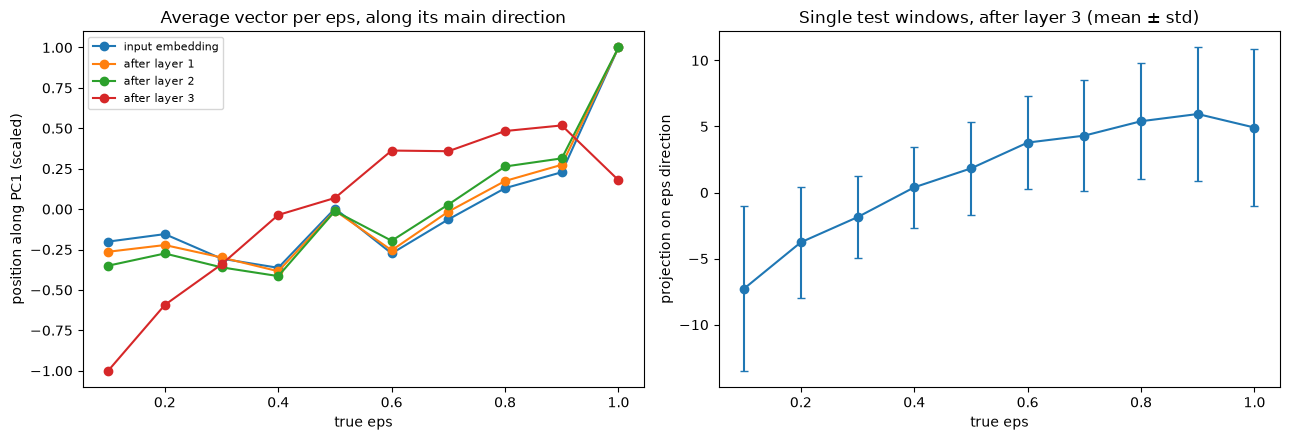

saved /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models/q2_eps_vectors.npz


In [11]:
# ==== Cell 11: plots for the eps direction, and save it for question 3 ====
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for k, stage in enumerate(STAGES):
    coord = (means_all[k] - means_all[k].mean(0)) @ pc1_all[k]
    axes[0].plot(eps_grid, coord / np.abs(coord).max(), marker="o", label=stage)
axes[0].set(xlabel="true eps", ylabel="position along PC1 (scaled)",
            title="Average vector per eps, along its main direction")
axes[0].legend(fontsize=8)

k = len(STAGES) - 1
Zt = test["hidden"][k][:, LATE].astype(np.float32).mean(axis=1)
proj = (Zt - means_all[k].mean(0)) @ pc1_all[k]
mean_p = [proj[np.isclose(test["eps"], e)].mean() for e in eps_grid]
std_p = [proj[np.isclose(test["eps"], e)].std() for e in eps_grid]
axes[1].errorbar(eps_grid, mean_p, yerr=std_p, marker="o", capsize=3)
axes[1].set(xlabel="true eps", ylabel="projection on eps direction",
            title=f"Single test windows, {STAGES[k]} (mean ± std)")

plt.tight_layout()
plt.show()

np.savez(OUT_DIR / "q2_eps_vectors.npz", eps_grid=eps_grid, stages=np.array(STAGES),
         means=np.stack(means_all), pc1=np.stack(pc1_all))
print("saved", OUT_DIR / "q2_eps_vectors.npz")

ceiling: model's own output vs true eps, corr² = 0.899

                 probe_corr2  direction_corr  order_kept_eps_01_09  \
stage                                                                
input embedding        0.000           0.179                  0.25   
after layer 1          0.383           0.263                  0.95   
after layer 2          0.516           0.467                  1.00   
after layer 3          0.579           0.642                  1.00   

                 eps_10_position  
stage                             
input embedding            0.251  
after layer 1              0.434  
after layer 2              0.479  
after layer 3             -0.996  


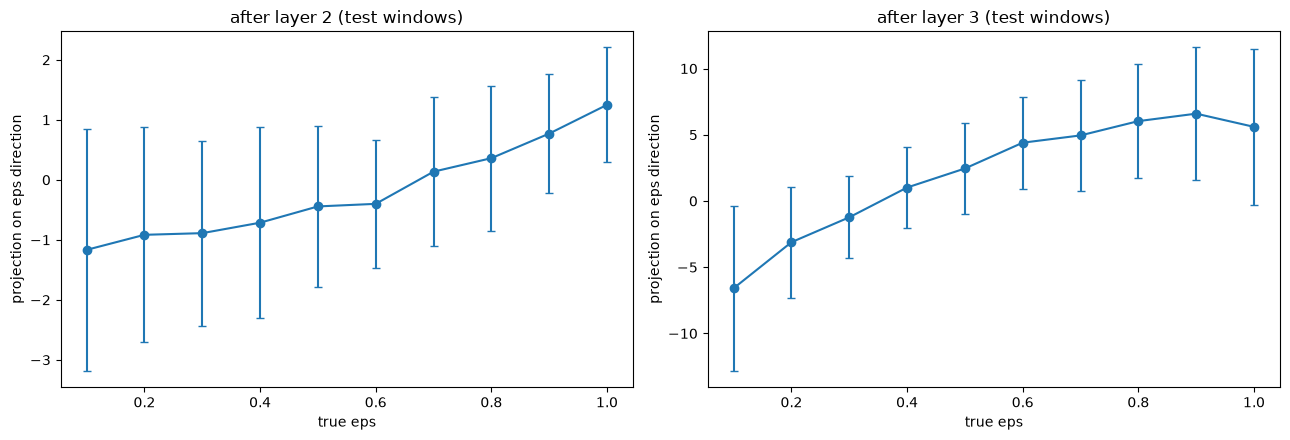

saved /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models/q2_eps_directions.npz


In [13]:
# ==== Cell 12: how much eps the model knows, and a cleaner eps direction ====
def corr2(a, b):
    return np.corrcoef(a, b)[0, 1] ** 2


def window_eps_hat(d):
    """Per window: the eps the model's OUTPUT implies, averaged over its late clear-choice steps."""
    W, L, _ = d["probs"].shape
    s = d["states"].reshape(-1, 19)
    clear = (n_ties(s) == 1).reshape(W, L)[:, LATE]
    best = best_dir(s).reshape(W, L)
    p_best = np.take_along_axis(d["probs"], best[..., None], axis=-1)[..., 0][:, LATE]
    eps_hat = np.clip((1 - p_best) / 0.75, 0, 1)
    n = clear.sum(1)
    return np.where(n > 0, (eps_hat * clear).sum(1) / np.maximum(n, 1), np.nan)


out_test = window_eps_hat(test)
ok = ~np.isnan(out_test)
ceiling = corr2(test["eps"][ok], out_test[ok])
print(f"ceiling: model's own output vs true eps, corr² = {ceiling:.3f}\n")

LOW, HIGH = [0.1, 0.2, 0.3], [0.7, 0.8, 0.9]      # eps = 1.0 left out on purpose
rows, directions, centers = [], [], []
for k, stage in enumerate(STAGES):
    Zv = val["hidden"][k][:, LATE].astype(np.float32).mean(axis=1)     # one vector per window
    Zt = test["hidden"][k][:, LATE].astype(np.float32).mean(axis=1)

    # 1) probe on window-averaged hidden states
    readout = ridge_fit(Zv.astype(np.float64), val["eps"].astype(np.float64))
    probe_c2 = corr2(test["eps"], readout(Zt.astype(np.float64)))

    # 2) direction = mean(high eps) - mean(low eps), from val windows
    low_mask = np.isclose(val["eps"][:, None], LOW).any(axis=1)
    high_mask = np.isclose(val["eps"][:, None], HIGH).any(axis=1)
    low = Zv[low_mask].mean(0)
    high = Zv[high_mask].mean(0)
    direction = (high - low) / np.linalg.norm(high - low)
    center = (high + low) / 2

    proj_t = (Zt - center) @ direction                                    # single test windows
    means = np.array([proj_t[np.isclose(test["eps"], e)].mean() for e in eps_grid])
    order_09 = pd.Series(means[:-1]).rank().corr(pd.Series(eps_grid[:-1]).rank())

    rows.append(dict(stage=stage,
                     probe_corr2=probe_c2,                                # vs the ceiling above
                     direction_corr=np.corrcoef(test["eps"], proj_t)[0, 1],
                     order_kept_eps_01_09=order_09,                       # want 1
                     eps_10_position=means[-1] - means[-2]))             # > 0: eps 1.0 stays in order
    directions.append(direction)
    centers.append(center)

print(pd.DataFrame(rows).set_index("stage").round(3))

# plot: single test windows projected on the cleaner direction, layers 2 and 3
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, k in zip(axes, [2, 3]):
    Zt = test["hidden"][k][:, LATE].astype(np.float32).mean(axis=1)
    proj_t = (Zt - centers[k]) @ directions[k]
    m = [proj_t[np.isclose(test["eps"], e)].mean() for e in eps_grid]
    sd = [proj_t[np.isclose(test["eps"], e)].std() for e in eps_grid]
    ax.errorbar(eps_grid, m, yerr=sd, marker="o", capsize=3)
    ax.set(xlabel="true eps", ylabel="projection on eps direction", title=f"{STAGES[k]} (test windows)")
plt.tight_layout()
plt.show()

np.savez(OUT_DIR / "q2_eps_directions.npz", stages=np.array(STAGES),
         directions=np.stack(directions), centers=np.stack(centers), low=LOW, high=HIGH)
print("saved", OUT_DIR / "q2_eps_directions.npz")

In [15]:
# ==== Cell 13 (corrected): square each step first, then average over clear-choice steps ====
def window_features(d, k, clear_only):
    """Per window: average of each hidden value and of its square, over late steps."""
    W, L, _ = d["probs"].shape
    H = d["hidden"][k][:, LATE].astype(np.float64)                  # (W, late steps, 64)
    if clear_only:
        s = d["states"].reshape(-1, 19)
        m = (n_ties(s) == 1).reshape(W, L)[:, LATE][..., None]      # (W, late steps, 1)
    else:
        m = np.ones(H.shape[:2] + (1,))
    n = np.maximum(m.sum(1), 1)
    lin = (H * m).sum(1) / n
    sq = (H ** 2 * m).sum(1) / n
    return lin, np.concatenate([lin, sq], axis=1)


rows = []
for k, stage in enumerate(STAGES):
    row = {"stage": stage}
    for clear_only in [False, True]:
        lin_v, both_v = window_features(val, k, clear_only)
        lin_t, both_t = window_features(test, k, clear_only)
        tag = "clear steps" if clear_only else "all steps"
        row[f"linear, {tag}"] = corr2(test["eps"], ridge_fit(lin_v, val["eps"].astype(np.float64))(lin_t))
        row[f"with squares, {tag}"] = corr2(test["eps"], ridge_fit(both_v, val["eps"].astype(np.float64))(both_t))
    rows.append(row)
print(pd.DataFrame(rows).set_index("stage").round(3))
print(f"ceiling (model's own output): {ceiling:.3f}")

                 linear, all steps  with squares, all steps  \
stage                                                         
input embedding              0.000                    0.133   
after layer 1                0.383                    0.395   
after layer 2                0.516                    0.507   
after layer 3                0.579                    0.569   

                 linear, clear steps  with squares, clear steps  
stage                                                            
input embedding                0.037                      0.115  
after layer 1                  0.404                      0.370  
after layer 2                  0.523                      0.497  
after layer 3                  0.586                      0.602  
ceiling (model's own output): 0.899


In [16]:
# ==== Cell 14: injection tools and the no-injection baseline ====
@torch.no_grad()
def run_with_injection(model, x, stage, vec):
    """Same as model(x), but adds `vec` (64 numbers) to the hidden state right after `stage`
    (0 = input embedding, 1-3 = after that layer), at every step. Returns action probabilities."""
    T = x.shape[1]
    h = model.inp(x) + model.pos(torch.arange(T, device=x.device))
    mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
    v = torch.as_tensor(vec, dtype=h.dtype, device=h.device)
    if stage == 0:
        h = h + v
    for i, layer in enumerate(model.blocks.layers, start=1):
        h = layer(h, src_mask=mask, is_causal=True)
        if stage == i:
            h = h + v
    return model.out(model.norm(h)).softmax(-1).cpu().numpy()


def windows_for_eps(data, eps_value, n=300, seed=0):
    """n random windows from ants whose true eps is eps_value. Returns model input and states."""
    X, Y, EPS = data
    ants, t0 = all_windows(len(X), X.shape[1], SEQ_LEN, SEQ_STRIDE)
    pool = np.flatnonzero(np.isclose(EPS[ants], eps_value))
    pick = np.random.default_rng(seed).choice(pool, size=min(n, len(pool)), replace=False)
    x, _, _ = get_batch(X, Y, EPS, ants[pick], t0[pick], SEQ_LEN)
    return x.to(DEVICE), x[..., :19].numpy()


def implied_eps(probs, states):
    """Per window: eps implied by the output, averaged over late clear-choice steps."""
    W, L, _ = probs.shape
    s = states.reshape(-1, 19)
    clear = (n_ties(s) == 1).reshape(W, L)[:, LATE]
    best = best_dir(s).reshape(W, L)
    p_best = np.take_along_axis(probs, best[..., None], axis=-1)[..., 0][:, LATE]
    e = np.clip((1 - p_best) / 0.75, 0, 1)
    n = clear.sum(1)
    return np.where(n > 0, (e * clear).sum(1) / np.maximum(n, 1), np.nan)


def rule_agreement(probs, states):
    """Share of late clear-choice steps where the model's top move is still the rule's best move."""
    W, L, _ = probs.shape
    s = states.reshape(-1, 19)
    clear = (n_ties(s) == 1).reshape(W, L)[:, LATE]
    best = best_dir(s).reshape(W, L)[:, LATE]
    return (probs.argmax(-1)[:, LATE] == best)[clear].mean()


def eps_vector(stage, target, source):
    """Paper-style vector: average hidden state of target-eps windows minus source-eps windows (val)."""
    M = means_all[stage]
    i_t = np.flatnonzero(np.isclose(eps_grid, target))[0]
    i_s = np.flatnonzero(np.isclose(eps_grid, source))[0]
    return M[i_t] - M[i_s]


def random_like(vec, rng):
    """A random direction with the same length as vec (the control)."""
    if np.linalg.norm(vec) == 0:
        return vec.copy()
    r = rng.normal(size=vec.shape)
    return r / np.linalg.norm(r) * np.linalg.norm(vec)


# Check: injecting zeros must give exactly the normal output
x_chk, _ = windows_for_eps(seq["test"], 0.5, n=32)
with torch.no_grad():
    normal = model_B(x_chk).softmax(-1).cpu().numpy()
print("zero-injection max difference:", np.abs(run_with_injection(model_B, x_chk, 2, np.zeros(64)) - normal).max())

# Baseline: what the model naturally implies for each eps (test windows, no injection)
baseline = {}
for e in eps_grid:
    x_e, s_e = windows_for_eps(seq["test"], e)
    baseline[round(float(e), 1)] = np.nanmean(implied_eps(run_with_injection(model_B, x_e, 2, np.zeros(64)), s_e))
print("\nnatural implied eps (no injection):")
print(pd.Series(baseline).round(3))

zero-injection max difference: 0.0

natural implied eps (no injection):
0.1    0.171
0.2    0.279
0.3    0.341
0.4    0.425
0.5    0.525
0.6    0.622
0.7    0.710
0.8    0.778
0.9    0.825
1.0    0.860
dtype: float64


In [17]:
# ==== Cell 15: does adding the eps vector change the model's randomness? (strength sweep) ====
PAIRS = [(0.2, 0.8), (0.8, 0.2)]       # (eps of the windows we run, eps of the vector we add)
INJECT_STAGES = [1, 2, 3]
ALPHAS = [0.0, 0.5, 1.0, 1.5, 2.0]     # vector strength; 1.0 = exactly the average difference
N_RANDOM = 5
rng = np.random.default_rng(0)

rows = []
for source, target in PAIRS:
    x_s, s_s = windows_for_eps(seq["test"], source)
    for stage in INJECT_STAGES:
        v = eps_vector(stage, target, source)
        randoms = [random_like(v, rng) for _ in range(N_RANDOM)]
        for a in ALPHAS:
            p = run_with_injection(model_B, x_s, stage, a * v)
            rows.append(dict(pair=f"{source}->{target}", stage=STAGES[stage], alpha=a, kind="eps vector",
                             implied=np.nanmean(implied_eps(p, s_s)), rule=rule_agreement(p, s_s)))
            imp, rule = [], []
            for r in randoms:
                p = run_with_injection(model_B, x_s, stage, a * r)
                imp.append(np.nanmean(implied_eps(p, s_s)))
                rule.append(rule_agreement(p, s_s))
            rows.append(dict(pair=f"{source}->{target}", stage=STAGES[stage], alpha=a, kind="random",
                             implied=np.mean(imp), rule=np.mean(rule)))

sweep = pd.DataFrame(rows)
print(sweep.pivot_table(index=["pair", "stage", "alpha"], columns="kind",
                        values=["implied", "rule"]).round(3))
print("\ngoals (natural implied eps of the target):",
      {f"{s}->{t}": round(baseline[t], 3) for s, t in PAIRS})

                                implied              rule       
kind                         eps vector random eps vector random
pair     stage         alpha                                    
0.2->0.8 after layer 1 0.0        0.279  0.279      0.999  0.999
                       0.5        0.315  0.281      0.999  0.999
                       1.0        0.354  0.284      0.999  0.999
                       1.5        0.399  0.288      0.999  0.999
                       2.0        0.448  0.294      0.999  0.999
         after layer 2 0.0        0.279  0.279      0.999  0.999
                       0.5        0.402  0.301      0.999  0.999
                       1.0        0.529  0.323      0.999  0.999
                       1.5        0.652  0.346      0.999  0.999
                       2.0        0.755  0.369      0.998  0.999
         after layer 3 0.0        0.279  0.279      0.999  0.999
                       0.5        0.332  0.281      0.999  0.999
                       1.

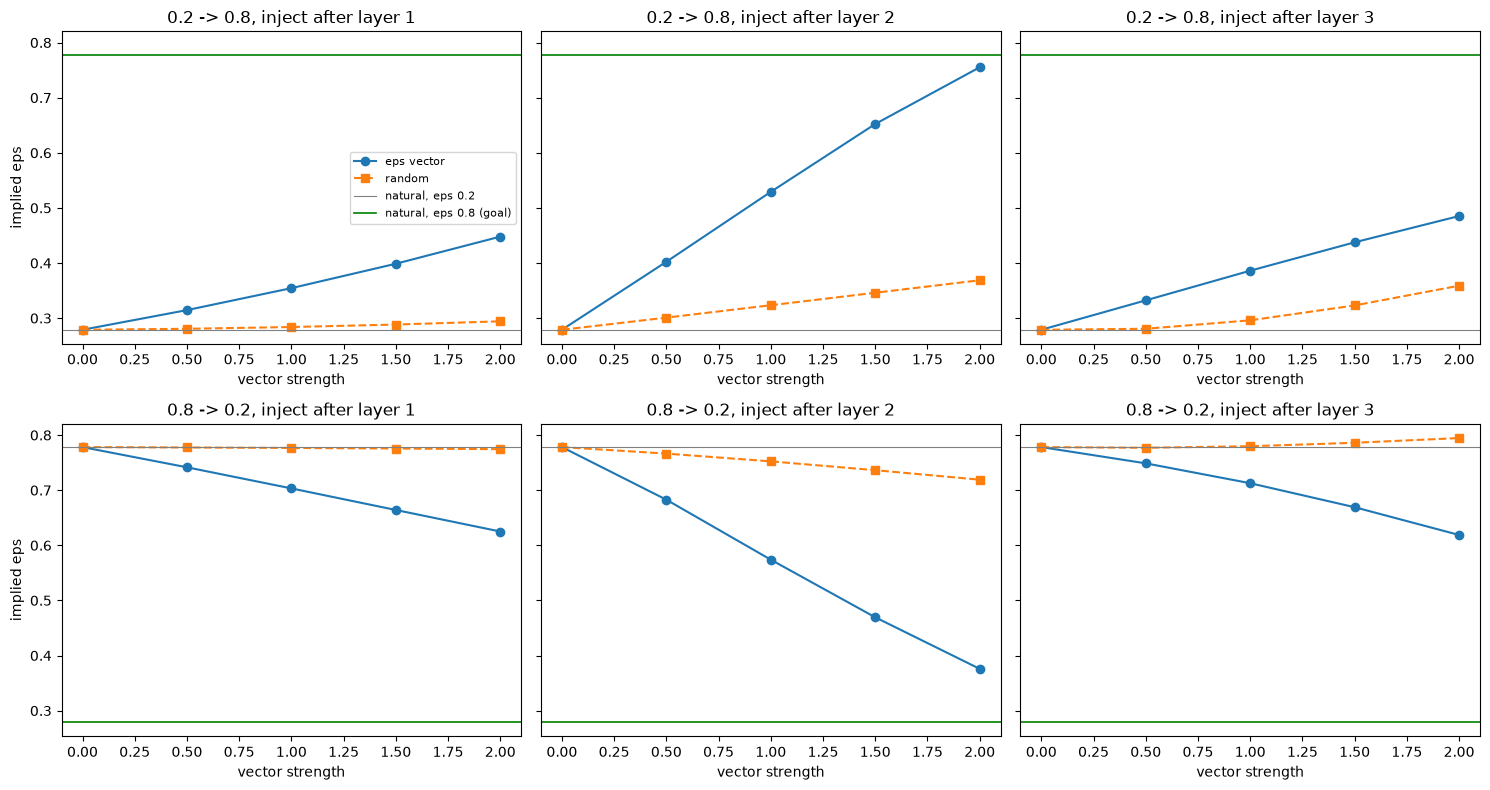

In [18]:
# ==== Cell 16: plot the strength sweep ====
fig, axes = plt.subplots(len(PAIRS), len(INJECT_STAGES), figsize=(15, 8), sharey=True)
for i, (source, target) in enumerate(PAIRS):
    for j, stage in enumerate(INJECT_STAGES):
        ax = axes[i, j]
        part = sweep[(sweep.pair == f"{source}->{target}") & (sweep.stage == STAGES[stage])]
        for kind, style in [("eps vector", "-o"), ("random", "--s")]:
            k = part[part.kind == kind]
            ax.plot(k.alpha, k.implied, style, label=kind)
        ax.axhline(baseline[source], color="gray", lw=0.8, label=f"natural, eps {source}")
        ax.axhline(baseline[target], color="green", lw=1.2, label=f"natural, eps {target} (goal)")
        ax.set(title=f"{source} -> {target}, inject {STAGES[stage]}", xlabel="vector strength")
        if j == 0:
            ax.set_ylabel("implied eps")
        if i == 0 and j == 0:
            ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

         goal  injected  random  rule_injected
target                                        
0.1     0.171     0.390   0.512          0.999
0.2     0.279     0.423   0.506          0.999
0.3     0.341     0.446   0.555          0.999
0.4     0.425     0.481   0.535          0.999
0.5     0.525     0.525   0.525          0.999
0.6     0.622     0.584   0.497          0.999
0.7     0.710     0.612   0.496          0.999
0.8     0.778     0.651   0.555          0.999
0.9     0.825     0.682   0.516          0.999
1.0     0.860     0.587   0.519          0.999

injected vs goal: corr 0.956, mean abs error 0.120
random vs goal:   corr -0.031


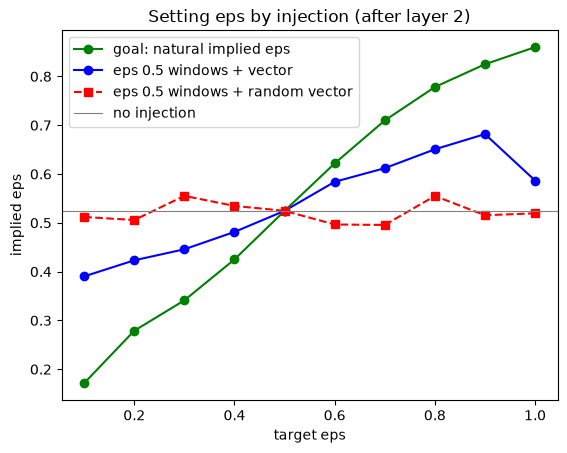

In [19]:
# ==== Cell 17: the knob: from one source, set every eps ====
BEST_STAGE = 2        # set this to the stage that worked best in Cells 15-16
SOURCE = 0.5
rng = np.random.default_rng(1)
x_s, s_s = windows_for_eps(seq["test"], SOURCE)

rows = []
for target in eps_grid:
    v = eps_vector(BEST_STAGE, target, SOURCE)
    p_inj = run_with_injection(model_B, x_s, BEST_STAGE, v)
    p_rnd = run_with_injection(model_B, x_s, BEST_STAGE, random_like(v, rng))
    rows.append(dict(target=round(float(target), 1),
                     goal=baseline[round(float(target), 1)],
                     injected=np.nanmean(implied_eps(p_inj, s_s)),
                     random=np.nanmean(implied_eps(p_rnd, s_s)),
                     rule_injected=rule_agreement(p_inj, s_s)))
knob = pd.DataFrame(rows).set_index("target")
print(knob.round(3))
print(f"\ninjected vs goal: corr {np.corrcoef(knob.goal, knob.injected)[0, 1]:.3f}, "
      f"mean abs error {np.abs(knob.goal - knob.injected).mean():.3f}")
print(f"random vs goal:   corr {np.corrcoef(knob.goal, knob.random)[0, 1]:.3f}")

plt.plot(knob.index, knob.goal, "g-o", label="goal: natural implied eps")
plt.plot(knob.index, knob.injected, "b-o", label=f"eps {SOURCE} windows + vector")
plt.plot(knob.index, knob.random, "r--s", label="eps 0.5 windows + random vector")
plt.axhline(baseline[SOURCE], color="gray", lw=0.8, label="no injection")
plt.xlabel("target eps")
plt.ylabel("implied eps")
plt.title(f"Setting eps by injection ({STAGES[BEST_STAGE]})")
plt.legend()
plt.show()

In [20]:
# ==== Cell 18: does injection win more when history is short? And the knob at strength 2 ====
POS_BUCKETS = {"0-7": slice(0, 8), "8-31": slice(8, 32), "32-63": slice(32, 64), "64-127": slice(64, SEQ_LEN)}


def implied_eps_at(probs, states, sl):
    """Average implied eps over clear-choice steps in the position range sl (all windows pooled)."""
    W, L, _ = probs.shape
    s = states.reshape(-1, 19)
    clear = (n_ties(s) == 1).reshape(W, L)[:, sl]
    best = best_dir(s).reshape(W, L)
    p_best = np.take_along_axis(probs, best[..., None], axis=-1)[..., 0][:, sl]
    return np.clip((1 - p_best) / 0.75, 0, 1)[clear].mean()


STAGE = 2
rows = []
for source, target in [(0.2, 0.8), (0.8, 0.2)]:
    x_s, s_s = windows_for_eps(seq["test"], source)
    x_t, s_t = windows_for_eps(seq["test"], target)
    p_none = run_with_injection(model_B, x_s, STAGE, np.zeros(64))
    p_goal = run_with_injection(model_B, x_t, STAGE, np.zeros(64))
    p_inj = run_with_injection(model_B, x_s, STAGE, eps_vector(STAGE, target, source))
    for name, sl in POS_BUCKETS.items():
        start = implied_eps_at(p_none, s_s, sl)
        goal = implied_eps_at(p_goal, s_t, sl)
        injected = implied_eps_at(p_inj, s_s, sl)
        rows.append(dict(pair=f"{source}->{target}", history=name, no_injection=start,
                         injected=injected, goal=goal,
                         share_of_way=(injected - start) / (goal - start)))   # 1 = reached the goal
print("strength 1, by history length:")
print(pd.DataFrame(rows).set_index(["pair", "history"]).round(3))

# knob at strength 2
ALPHA = 2.0
x_s, s_s = windows_for_eps(seq["test"], SOURCE)
rng = np.random.default_rng(2)
rows = []
for target in eps_grid:
    v = ALPHA * eps_vector(STAGE, target, SOURCE)
    rows.append(dict(target=round(float(target), 1), goal=baseline[round(float(target), 1)],
                     injected=np.nanmean(implied_eps(run_with_injection(model_B, x_s, STAGE, v), s_s)),
                     random=np.nanmean(implied_eps(run_with_injection(model_B, x_s, STAGE, random_like(v, rng)), s_s))))
knob2 = pd.DataFrame(rows).set_index("target")
print(f"\nknob at strength {ALPHA}:")
print(knob2.round(3))
clean = knob2.index <= 0.9
print(f"eps 0.1-0.9: mean abs error {np.abs(knob2.goal - knob2.injected)[clean].mean():.3f}, "
      f"random {np.abs(knob2.goal - knob2.random)[clean].mean():.3f}")

strength 1, by history length:
                  no_injection  injected   goal  share_of_way
pair     history                                             
0.2->0.8 0-7             0.380     0.585  0.652         0.755
         8-31            0.302     0.527  0.743         0.511
         32-63           0.280     0.518  0.773         0.483
         64-127          0.266     0.511  0.780         0.478
0.8->0.2 0-7             0.652     0.468  0.380         0.677
         8-31            0.743     0.557  0.302         0.421
         32-63           0.773     0.580  0.280         0.393
         64-127          0.780     0.585  0.266         0.379

knob at strength 2.0:
         goal  injected  random
target                         
0.1     0.171     0.263   0.578
0.2     0.279     0.329   0.529
0.3     0.341     0.376   0.542
0.4     0.425     0.445   0.581
0.5     0.525     0.525   0.525
0.6     0.622     0.636   0.517
0.7     0.710     0.690   0.539
0.8     0.778     0.757   0.485
0.9   

In [21]:
# ==== Cell 19: choose the injection strength on VALIDATION, report once on TEST ====
STAGE = 2
SOURCE = 0.5
ALPHA_GRID = [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
TARGETS = [round(float(e), 1) for e in eps_grid if e <= 0.9 + 1e-6]


def natural_reading(model, data, seed):
    """Implied eps the model reaches on its own (no injection), for every eps."""
    out = {}
    for e in eps_grid:
        x_e, s_e = windows_for_eps(data, e, seed=seed)
        out[round(float(e), 1)] = np.nanmean(implied_eps(run_with_injection(model, x_e, STAGE, np.zeros(64)), s_e))
    return out


def knob_error(model, M, data, goals, alpha, source, targets, seed):
    """Average |implied - goal| when injecting alpha * (M[target] - M[source]) into source windows."""
    x_s, s_s = windows_for_eps(data, source, seed=seed)
    errs = []
    for t in targets:
        p = run_with_injection(model, x_s, STAGE, alpha * (M[t] - M[source]))
        errs.append(abs(np.nanmean(implied_eps(p, s_s)) - goals[t]))
    return np.mean(errs)


M_B = {round(float(e), 1): means_all[STAGE][i] for i, e in enumerate(eps_grid)}   # model B's eps vectors (val)
val_goals = natural_reading(model_B, seq["val"], seed=10)
val_err = {a: knob_error(model_B, M_B, seq["val"], val_goals, a, SOURCE, TARGETS, seed=10) for a in ALPHA_GRID}
print("validation error by strength:", {a: round(e, 4) for a, e in val_err.items()})

ALPHA_VAL = min(val_err, key=val_err.get)
test_err = knob_error(model_B, M_B, seq["test"], baseline, ALPHA_VAL, SOURCE, TARGETS, seed=0)
print(f"\nstrength chosen on validation: {ALPHA_VAL}")
print(f"TEST error, eps 0.1-0.9: {test_err:.3f}")

validation error by strength: {1.0: np.float64(0.1062), 1.25: np.float64(0.0856), 1.5: np.float64(0.0658), 1.75: np.float64(0.0491), 2.0: np.float64(0.0337), 2.5: np.float64(0.023), 3.0: np.float64(0.0318)}

strength chosen on validation: 2.5
TEST error, eps 0.1-0.9: 0.015


In [22]:
# ==== Cell 20: retrain model B with two eps values left out of training (about 3 min) ====
HELD_OUT = [0.4, 0.7]


def train_seq_model(model, data, epochs=20, batch=256, lr=3e-4):
    X, Y, EPS = data
    ants, t0 = all_windows(len(X), X.shape[1], SEQ_LEN, SEQ_STRIDE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for epoch in range(1, epochs + 1):
        order = np.random.permutation(len(ants))
        start_time, total, count = time.time(), 0.0, 0
        for start in range(0, len(order), batch):
            sel = order[start:start + batch]
            x, y, _ = get_batch(X, Y, EPS, ants[sel], t0[sel], SEQ_LEN)
            loss = nn.functional.cross_entropy(model(x.to(DEVICE)).reshape(-1, N_ACTIONS),
                                               y.reshape(-1).to(DEVICE))
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item()
            count += 1
        print(f"   epoch {epoch:>2}: loss {total / count:.4f}   ({time.time() - start_time:.0f} s)")
    model.eval()


train_runs = [load_run(p.parent) for p in sorted((DATA_DIR / "train").glob("*/traj.npz"))]
train_runs = [r for r in train_runs if not np.isclose(r["eps"], HELD_OUT).any()]
print("training eps values:", sorted({r["eps"] for r in train_runs}))
train_B = build_sequences_B(train_runs)
del train_runs

model_H = AntGPT(d_in=cfg["d_in_B"]).to(DEVICE)
train_seq_model(model_H, train_B)
del train_B
torch.save(model_H.state_dict(), OUT_DIR / "seq_B_heldout_04_07.pt")

training eps values: [0.1, 0.2, 0.3, 0.5, 0.6, 0.8, 0.9, 1.0]
   epoch  1: loss 1.2289   (6 s)
   epoch  2: loss 1.1728   (6 s)
   epoch  3: loss 1.1590   (6 s)
   epoch  4: loss 1.1544   (6 s)
   epoch  5: loss 1.1524   (6 s)
   epoch  6: loss 1.1509   (6 s)
   epoch  7: loss 1.1500   (6 s)
   epoch  8: loss 1.1492   (6 s)
   epoch  9: loss 1.1486   (6 s)
   epoch 10: loss 1.1479   (6 s)
   epoch 11: loss 1.1476   (6 s)
   epoch 12: loss 1.1472   (6 s)
   epoch 13: loss 1.1468   (6 s)
   epoch 14: loss 1.1465   (6 s)
   epoch 15: loss 1.1461   (6 s)
   epoch 16: loss 1.1459   (6 s)
   epoch 17: loss 1.1456   (6 s)
   epoch 18: loss 1.1453   (6 s)
   epoch 19: loss 1.1451   (6 s)
   epoch 20: loss 1.1448   (6 s)


In [23]:
# ==== Cell 21: does the held-out model read, and can it be SET to, eps it never saw? ====
HO = [round(e, 1) for e in HELD_OUT]
TRAINED = [t for t in TARGETS if t not in HO]

# 1) Reading: natural implied eps on test windows, for every eps
reading_H = natural_reading(model_H, seq["test"], seed=0)
reading = pd.DataFrame({"model B (all eps)": pd.Series(baseline), "held-out model": pd.Series(reading_H)})
reading["held out?"] = ["yes" if e in HO else "" for e in reading.index]
print("natural implied eps, test windows:")
print(reading.round(3))

# 2) The held-out model's eps vectors (val windows), and interpolated ones for the held-out eps
val_H = collect_hidden(model_H, seq["val"], seed=0)
Zh = val_H["hidden"][STAGE][:, LATE].astype(np.float32).mean(axis=1)
M_H = {round(float(e), 1): Zh[np.isclose(val_H["eps"], e)].mean(0) for e in eps_grid}
M_interp = {h: (M_H[round(h - 0.1, 1)] + M_H[round(h + 0.1, 1)]) / 2 for h in HO}   # from neighbors only

# 3) Strength for this model, chosen on validation using TRAINED targets only
goals_val_H = natural_reading(model_H, seq["val"], seed=10)
err_H = {a: knob_error(model_H, M_H, seq["val"], goals_val_H, a, 0.5, [t for t in TRAINED if t != 0.5], seed=10)
         for a in ALPHA_GRID}
ALPHA_H = min(err_H, key=err_H.get)
print(f"\nheld-out model strength (chosen on val, trained eps only): {ALPHA_H}")

# 4) Inject toward each held-out eps from far-away trained sources
rng = np.random.default_rng(3)
rows = []
for source in [0.1, 0.9]:
    x_s, s_s = windows_for_eps(seq["test"], source)
    for h in HO:
        row = dict(source=source, held_out_eps=h, start=reading_H[source], goal=reading_H[h])
        for kind, vec in [("interpolated vector", M_interp[h] - M_H[source]),
                          ("real-mean vector (reference)", M_H[h] - M_H[source])]:
            p = run_with_injection(model_H, x_s, STAGE, ALPHA_H * vec)
            row[kind] = np.nanmean(implied_eps(p, s_s))
        p = run_with_injection(model_H, x_s, STAGE, random_like(ALPHA_H * (M_interp[h] - M_H[source]), rng))
        row["random"] = np.nanmean(implied_eps(p, s_s))
        rows.append(row)
print("\nsetting held-out eps by injection (test windows):")
print(pd.DataFrame(rows).set_index(["source", "held_out_eps"]).round(3))

natural implied eps, test windows:
     model B (all eps)  held-out model held out?
0.1              0.171           0.162          
0.2              0.279           0.270          
0.3              0.341           0.332          
0.4              0.425           0.408       yes
0.5              0.525           0.523          
0.6              0.622           0.622          
0.7              0.710           0.713       yes
0.8              0.778           0.777          
0.9              0.825           0.820          
1.0              0.860           0.848          

held-out model strength (chosen on val, trained eps only): 2.5

setting held-out eps by injection (test windows):
                     start   goal  interpolated vector  \
source held_out_eps                                      
0.1    0.4           0.162  0.408                0.386   
       0.7           0.162  0.713                0.672   
0.9    0.4           0.820  0.408                0.413   
       0.7           

In [24]:
# ==== Cell 22: closed-loop tools ====
import sys
sys.path.insert(0, str(PROJECT))
from simulation import Simulation
from config import Config

sim_mod = sys.modules[Simulation.__module__]
FOOD_PATCHES = [(80, 80), (20, 75)]     # must match how the dataset runs placed food


@torch.no_grad()
def run_with_injection(model, x, stage, vec):
    """As before, but vec can be (64,) for all windows or (B, 64) for one vector per window."""
    T = x.shape[1]
    h = model.inp(x) + model.pos(torch.arange(T, device=x.device))
    mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
    v = torch.as_tensor(vec, dtype=h.dtype, device=h.device)
    if v.dim() == 2:
        v = v[:, None, :]
    if stage == 0:
        h = h + v
    for i, layer in enumerate(model.blocks.layers, start=1):
        h = layer(h, src_mask=mask, is_causal=True)
        if stage == i:
            h = h + v
    return model.out(model.norm(h)).softmax(-1).cpu().numpy()


def obs_from(ant, local):
    return np.concatenate([[float(local.on_food), float(local.at_home), float(ant.carrying)],
                           local.see_food, local.see_home,
                           local.smell_food, local.smell_home]).astype(np.float32)


def run_colony(policy, seed, T=1500):
    """All ants sense, then one batched decision for all ants, then all act.
    (Slightly different order from the original one-ant-at-a-time loop, so the real rule
    is always run through this same loop as the reference.)"""
    sim = Simulation(Config(seed=seed))          # Config's epsilon is unused: the policy decides
    for x, y in FOOD_PATCHES:
        sim.world.add_food(x, y, radius=4, amount_per_cell=5)
    rng = np.random.default_rng(seed + 1000)
    policy.reset(len(sim.ants))
    log_obs, log_act, log_target = [], [], []
    for t in range(T):
        locals_ = [sim_mod.sense(a, sim.world) for a in sim.ants]
        obs = np.stack([obs_from(a, l) for a, l in zip(sim.ants, locals_)])    # (N, 19) raw
        probs, target = policy.act_probs(obs)
        act = np.minimum((rng.random((len(obs), 1)) > probs.cumsum(1)).sum(1), N_ACTIONS - 1)
        policy.observe(act)
        for ant, local, d in zip(sim.ants, locals_, act):
            was_carrying = ant.carrying
            if local.on_food and not ant.carrying:
                sim_mod.pick_food(ant, sim.world)
            elif local.at_home and ant.carrying:
                sim_mod.drop_food(ant, sim.world)
            step = np.zeros(N_ACTIONS)
            step[d] = 1.0
            sim_mod.move(ant, step, sim.world)
            sim_mod.drop_pheromone(ant, sim.world)
            if ant.carrying == was_carrying:
                ant.steps_since_event += 1
        sim.world.update()
        sim.t += 1
        log_obs.append(obs)
        log_act.append(act)
        log_target.append(target)
    return dict(obs=np.stack(log_obs), act=np.stack(log_act), target=np.stack(log_target),
                delivered=sim.world.food_delivered)


# Controller pieces: eps vectors (val) and the model's reading scale (val), for mapping back and forth
BASE_EPS = np.array(sorted(val_goals))
BASE_READ = np.maximum.accumulate(np.array([val_goals[e] for e in BASE_EPS]))    # model-scale readings
M_STAGE = means_all[STAGE]                                                        # (10, 64)


def mean_at(eps_values):
    """eps vector at any eps (linear interpolation between the 10 measured ones). (N,) -> (N, 64)"""
    e = np.clip(eps_values, eps_grid[0], eps_grid[-1])
    return np.stack([np.interp(e, eps_grid, M_STAGE[:, j]) for j in range(M_STAGE.shape[1])], axis=1)


def window_reading(probs, states, min_clear=5):
    """Per ant: eps implied by the model's own output over its window (model scale)."""
    W, L, _ = probs.shape
    s = states.reshape(-1, 19)
    clear = (n_ties(s) == 1).reshape(W, L)
    best = best_dir(s).reshape(W, L)
    p_best = np.take_along_axis(probs, best[..., None], axis=-1)[..., 0]
    e = np.clip((1 - p_best) / 0.75, 0, 1)
    n = clear.sum(1)
    return np.where(n >= min_clear, (e * clear).sum(1) / np.maximum(n, 1), np.interp(0.5, BASE_EPS, BASE_READ))


class RulePolicy:
    """The real rule, with the eps chosen per ant by target_fn(raw obs)."""
    def __init__(self, target_fn):
        self.target_fn = target_fn

    def reset(self, n):
        pass

    def act_probs(self, obs):
        target = self.target_fn(obs)
        return true_probs(obs, target), target

    def observe(self, act):
        pass


class ModelPolicy:
    """Model B acts as the ant, reading its own last SEQ_LEN steps.
    With target_fn: each step, read the believed eps, then add alpha * (vec[target] - vec[believed]) at layer 2."""
    def __init__(self, model, target_fn=None, alpha=1.0):
        self.model, self.target_fn, self.alpha = model, target_fn, alpha

    def reset(self, n):
        self.buf = np.zeros((n, SEQ_LEN, 27), dtype=np.float32)
        self.len = 0
        self.prev = np.zeros((n, 4), dtype=np.float32)

    def act_probs(self, obs):
        s = normalize(obs)
        token = np.concatenate([s, brain_probs(s), self.prev], axis=1)            # (N, 27)
        if self.len < SEQ_LEN:
            self.buf[:, self.len] = token
            self.len += 1
        else:
            self.buf = np.roll(self.buf, -1, axis=1)
            self.buf[:, -1] = token
        x = torch.from_numpy(self.buf[:, :self.len]).to(DEVICE)

        with torch.no_grad():
            p0 = self.model(x).softmax(-1).cpu().numpy()                           # no injection
        if self.target_fn is None:
            return p0[:, -1], np.full(len(obs), np.nan)

        target = self.target_fn(obs)
        believed = np.interp(window_reading(p0, self.buf[:, :self.len, :19]), BASE_READ, BASE_EPS)
        vec = self.alpha * (mean_at(target) - mean_at(believed))                    # push belief -> target
        probs = run_with_injection(self.model, x, STAGE, vec)[:, -1]
        return probs, target

    def observe(self, act):
        self.prev = np.eye(4, dtype=np.float32)[act]


def realized(log, warmup=200):
    """Measured randomness from the ants' actual moves: eps = (1 - follow rate) / 0.75 on clear steps."""
    obs = log["obs"][warmup:].reshape(-1, 19)
    act = log["act"][warmup:].reshape(-1)
    clear = n_ties(obs) == 1
    follow = act == best_dir(obs)
    carrying = obs[:, CARRYING] > 0.5
    out = {}
    for name, m in [("all", clear), ("searching", clear & ~carrying), ("carrying", clear & carrying)]:
        out[name] = (1 - follow[m].mean()) / 0.75 if m.any() else np.nan
    return out

In [26]:
# ==== Cell 23: run the closed-loop experiments (about 10 min) ====
CONDITIONS = {
    "eps 0.1": lambda o: np.full(len(o), 0.1),
    "eps 0.5": lambda o: np.full(len(o), 0.5),
    "eps 0.9": lambda o: np.full(len(o), 0.9),
    "0.1 carrying / 0.6 searching": lambda o: np.where(o[:, CARRYING] > 0.5, 0.1, 0.6),
}
SEEDS = [0, 1]
T_STEPS = 1500

def true_probs(s, eps):
    """True action probabilities: brain with prob 1-eps (split over tied best dirs), uniform with prob eps."""
    sig = signal(s)
    is_best = sig == sig.max(axis=1, keepdims=True)
    k = is_best.sum(axis=1, keepdims=True)
    eps = np.asarray(eps, dtype=np.float64).reshape(-1, 1)
    return is_best * (1 - eps) / k + eps / N_ACTIONS

rows = []
for seed in SEEDS:
    start = time.time()
    log = run_colony(ModelPolicy(model_B), seed, T_STEPS)
    rows.append(dict(condition="no target", policy="model, no injection", seed=seed,
                     delivered=log["delivered"], **realized(log)))
    print(rows[-1], f"({time.time() - start:.0f} s)")
    for name, fn in CONDITIONS.items():
        for policy_name, policy in [("real rule", RulePolicy(fn)),
                                    ("model + controller", ModelPolicy(model_B, fn, alpha=ALPHA_VAL))]:
            start = time.time()
            log = run_colony(policy, seed, T_STEPS)
            rows.append(dict(condition=name, policy=policy_name, seed=seed,
                             delivered=log["delivered"], **realized(log)))
            print(rows[-1], f"({time.time() - start:.0f} s)")

closed = pd.DataFrame(rows)
closed.to_csv(OUT_DIR / "q3_closed_loop.csv", index=False)

{'condition': 'no target', 'policy': 'model, no injection', 'seed': 0, 'delivered': 142, 'all': np.float64(0.6199656693762324), 'searching': np.float64(0.6188155973194666), 'carrying': np.float64(0.6212101073649078)} (7 s)
{'condition': 'eps 0.1', 'policy': 'real rule', 'seed': 0, 'delivered': 295, 'all': np.float64(0.09961344919971138), 'searching': np.float64(0.09885821269414337), 'carrying': np.float64(0.10187709938747276)} (3 s)
{'condition': 'eps 0.1', 'policy': 'model + controller', 'seed': 0, 'delivered': 245, 'all': np.float64(0.17941594301977717), 'searching': np.float64(0.18407189725409712), 'carrying': np.float64(0.16294927631868372)} (14 s)
{'condition': 'eps 0.5', 'policy': 'real rule', 'seed': 0, 'delivered': 273, 'all': np.float64(0.5), 'searching': np.float64(0.5003406723899628), 'carrying': np.float64(0.4996222179047125)} (3 s)
{'condition': 'eps 0.5', 'policy': 'model + controller', 'seed': 0, 'delivered': 200, 'all': np.float64(0.5404520509720027), 'searching': np.fl

                                                    all  searching  carrying  \
condition                    policy                                            
0.1 carrying / 0.6 searching model + controller   0.581      0.690     0.177   
                             real rule            0.472      0.599     0.102   
eps 0.1                      model + controller   0.178      0.185     0.161   
                             real rule            0.101      0.100     0.103   
eps 0.5                      model + controller   0.541      0.525     0.558   
                             real rule            0.501      0.499     0.502   
eps 0.9                      model + controller   0.887      0.886     0.888   
                             real rule            0.903      0.902     0.907   
no target                    model, no injection  0.605      0.606     0.604   

                                                  delivered  
condition                    policy                      

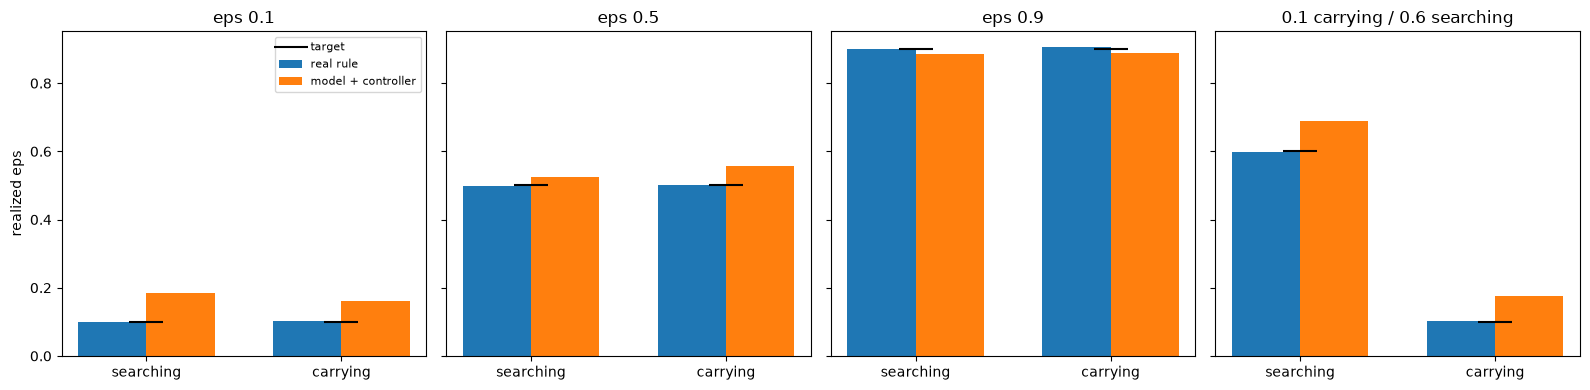

In [27]:
# ==== Cell 24: closed-loop summary ====
summary = closed.groupby(["condition", "policy"])[["all", "searching", "carrying", "delivered"]].mean()
print(summary.round(3))

targets = {"eps 0.1": (0.1, 0.1), "eps 0.5": (0.5, 0.5), "eps 0.9": (0.9, 0.9),
           "0.1 carrying / 0.6 searching": (0.6, 0.1)}         # (searching, carrying)

fig, axes = plt.subplots(1, len(targets), figsize=(16, 4), sharey=True)
for ax, (name, (t_search, t_carry)) in zip(axes, targets.items()):
    part = summary.loc[name]
    xs = np.arange(2)
    for i, policy in enumerate(["real rule", "model + controller"]):
        ax.bar(xs + (i - 0.5) * 0.35, part.loc[policy, ["searching", "carrying"]], width=0.35, label=policy)
    ax.scatter(xs, [t_search, t_carry], color="black", marker="_", s=600, zorder=3, label="target")
    ax.set_xticks(xs)
    ax.set_xticklabels(["searching", "carrying"])
    ax.set_title(name)
axes[0].set_ylabel("realized eps")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()